In [ ]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:9 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Fetched 3,917 B in 1s (2,807 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependen

In [ ]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Overwriting main.cpp


In [ ]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [ ]:
%%writefile setup.sh
#!/bin/bash
echo "[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor..."
apt-get update -qq && apt-get install -y -qq libopencv-dev build-essential cmake > /dev/null

echo "[2/3] C++ uygulaması derleniyor..."
g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart

echo "[3/3] Uygulama çalıştırılıyor..."
./app

Overwriting setup.sh


In [ ]:
!bash setup.sh

[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[2/3] C++ uygulaması derleniyor...
[3/3] Uygulama çalıştırılıyor...
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


Saving resim2.jpeg to resim2 (3).jpeg
Ortak merkez: (np.int64(147), np.int64(153))
Bulunan yaricaplar: [12 24 48]


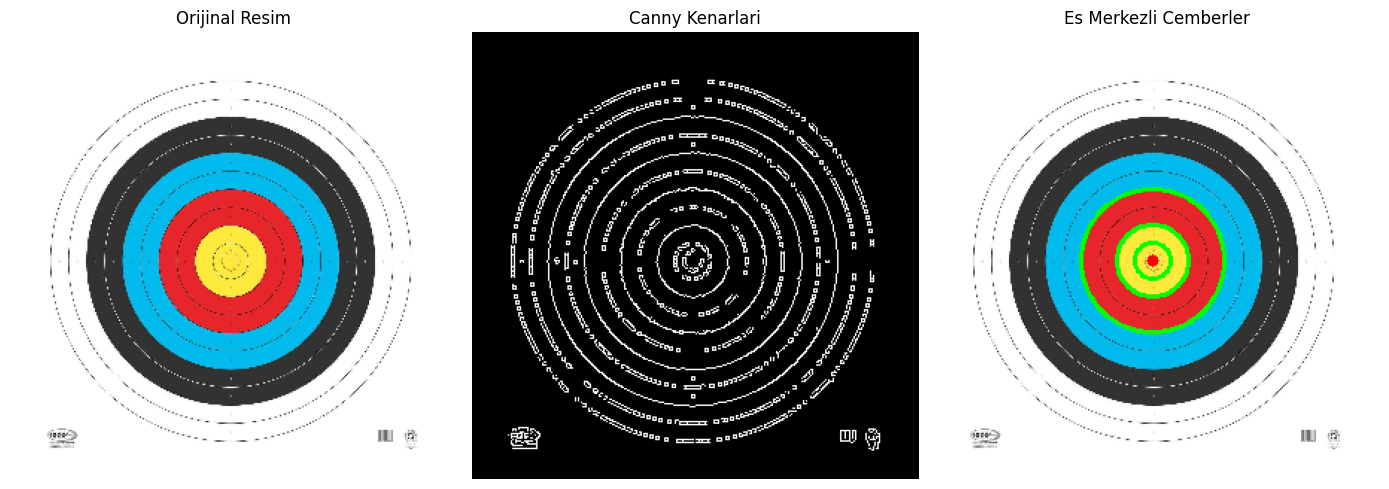

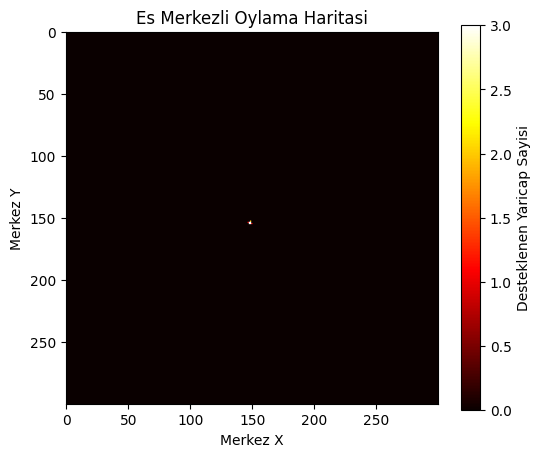

In [6]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Resmi yukle
yuklenen = files.upload()
dosya_adi = list(yuklenen.keys())[0]

resim = cv2.imdecode(
    np.frombuffer(yuklenen[dosya_adi], np.uint8),
    cv2.IMREAD_COLOR
)

if resim is None:
    raise ValueError("Resim okunamadi!")

# Resmi kucult (hiz icin)
h, w = resim.shape[:2]
if max(h, w) > 300:
    oran = 300 / max(h, w)
    resim = cv2.resize(resim, None, fx=oran, fy=oran)

# 2. Canny kenar tespiti
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)
kenarlar = cv2.Canny(gri, 50, 150)

H, W = kenarlar.shape

# 3. Sin ve cos degerlerini onceden hesapla
acilar = np.deg2rad(np.arange(0, 360, 10))
sin_tablosu = np.sin(acilar)
cos_tablosu = np.cos(acilar)

# 4. Yaricap araligi
yaricaplar = np.arange(10, 101, 2)

# 5. 3 boyutlu oylama matrisi
# Boyut: [yaricap, merkez_y, merkez_x]
oylama = np.zeros(
    (len(yaricaplar), H, W),
    dtype=np.uint32
)

# Kenar noktalarini bul
ys, xs = np.where(kenarlar > 0)

# 6. Hough oylamasi
for ri, r in enumerate(yaricaplar):
    for x, y in zip(xs, ys):
        for s, c in zip(sin_tablosu, cos_tablosu):

            a = int(round(x - r * c))
            b = int(round(y - r * s))

            if 0 <= a < W and 0 <= b < H:
                oylama[ri, b, a] += 1

# 7. ES MERKEZLI OYLAMA
# Ayni merkezde birden fazla yaricap oy almali
esik = 18
min_cember = 2

# Her merkezde kac farkli yaricap esigi geciyor?
es_merkez_oy = np.sum(oylama >= esik, axis=0)

# Es merkezli aday merkezleri bul
merkezler = np.argwhere(es_merkez_oy >= min_cember)

# 8. En guclu merkezi sec
sonuc = resim.copy()

if len(merkezler) > 0:

    # En cok farkli yaricap destegi alan merkez
    puanlar = es_merkez_oy[
        merkezler[:, 0],
        merkezler[:, 1]
    ]

    en_iyi = np.argmax(puanlar)
    b, a = merkezler[en_iyi]

    # Bu merkezde esigi gecen yaricaplar
    uygun_r = yaricaplar[oylama[:, b, a] >= esik]

    for r in uygun_r:
        cv2.circle(
            sonuc, (int(a), int(b)),
            int(r), (0, 255, 0), 2
        )

    # Ortak merkezi kirmizi goster
    cv2.circle(
        sonuc, (int(a), int(b)),
        4, (0, 0, 255), -1
    )

    print("Ortak merkez:", (a, b))
    print("Bulunan yaricaplar:", uygun_r)

else:
    print("Es merkezli cember bulunamadi.")

# 9. Sonuclari goster
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Resim")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(kenarlar, cmap="gray")
plt.title("Canny Kenarlari")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(sonuc, cv2.COLOR_BGR2RGB))
plt.title("Es Merkezli Cemberler")
plt.axis("off")

plt.tight_layout()
plt.show()

# 10. Es merkezli oy haritasini goster
plt.figure(figsize=(6, 5))
plt.imshow(es_merkez_oy, cmap="hot")
plt.colorbar(label="Desteklenen Yaricap Sayisi")
plt.title("Es Merkezli Oylama Haritasi")
plt.xlabel("Merkez X")
plt.ylabel("Merkez Y")
plt.show()
